In [1]:
import torch 

# Tensor and Operations

In [2]:
z= torch.zeros(5,3)
print(z)
print(z.dtype)

tensor([[0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.]])
torch.float32


In [4]:
i= torch.ones((5,3), dtype=torch.int16)
print(i, i.dtype)

tensor([[1, 1, 1],
        [1, 1, 1],
        [1, 1, 1],
        [1, 1, 1],
        [1, 1, 1]], dtype=torch.int16) torch.int16


In [6]:
torch.manual_seed(663)

r1=torch.rand(2,2)
print(f"r1: {r1}", r1.dtype)

r2= torch.rand(2,2)
print(f"r2: {r2}", r2.dtype)

torch.manual_seed(663)
r3= torch.rand(2,2)
print(f"r3: {r3}", r3.dtype)

r1: tensor([[0.4586, 0.4786],
        [0.0712, 0.0323]]) torch.float32
r2: tensor([[0.8977, 0.6031],
        [0.4881, 0.4650]]) torch.float32
r3: tensor([[0.4586, 0.4786],
        [0.0712, 0.0323]]) torch.float32


In [8]:
ones= torch.ones((2,3))
print(ones, ones.shape)

twos= torch.ones((2,3))*2
print(twos, twos.shape)

threes= twos+ones
print(threes, threes.shape)

tensor([[1., 1., 1.],
        [1., 1., 1.]]) torch.Size([2, 3])
tensor([[2., 2., 2.],
        [2., 2., 2.]]) torch.Size([2, 3])
tensor([[3., 3., 3.],
        [3., 3., 3.]]) torch.Size([2, 3])


In [20]:
r= torch.rand((2,2))-0.5*2
print(r)

print(torch.abs(r))

print("\ninverse sin of r")
print(torch.asin(r))

print("\nDeterminant of r")
print(torch.det(r))

print("\nSingular value of decomposion of r: ")
print(torch.svd(r))

print("\nAverage & Standard deviation of r: ")
print(torch.std_mean(r))

print("\nMaximum of r")
print(torch.max(r))

tensor([[-0.0266, -0.6848],
        [-0.4608, -0.7126]])
tensor([[0.0266, 0.6848],
        [0.4608, 0.7126]])

inverse sin of r
tensor([[-0.0266, -0.7544],
        [-0.4789, -0.7932]])

Determinant of r
tensor(-0.2966)

Singular value of decomposion of r: 
torch.return_types.svd(
U=tensor([[-0.6153, -0.7883],
        [-0.7883,  0.6153]]),
S=tensor([1.0538, 0.2815]),
V=tensor([[ 0.3603, -0.9329],
        [ 0.9329,  0.3603]]))

Average & Standard deviation of r: 
(tensor(0.3171), tensor(-0.4712))

Maximum of r
tensor(-0.0266)


# Automatic Differentiation Engine

In [ ]:
x= torch.rand(1, 10)

prev_h= torch.rand(1, 20)
W_h= torch.rand(20,20)
W_x= torch.rand(20, 10)

i2h= torch.mm(W_x,x.t())
h2h= torch.mm(W_h, prev_h.t())

next_h= i2h+h2h
next_h= next_h.tanh()

loss= next_h.sum()
loss.backward()

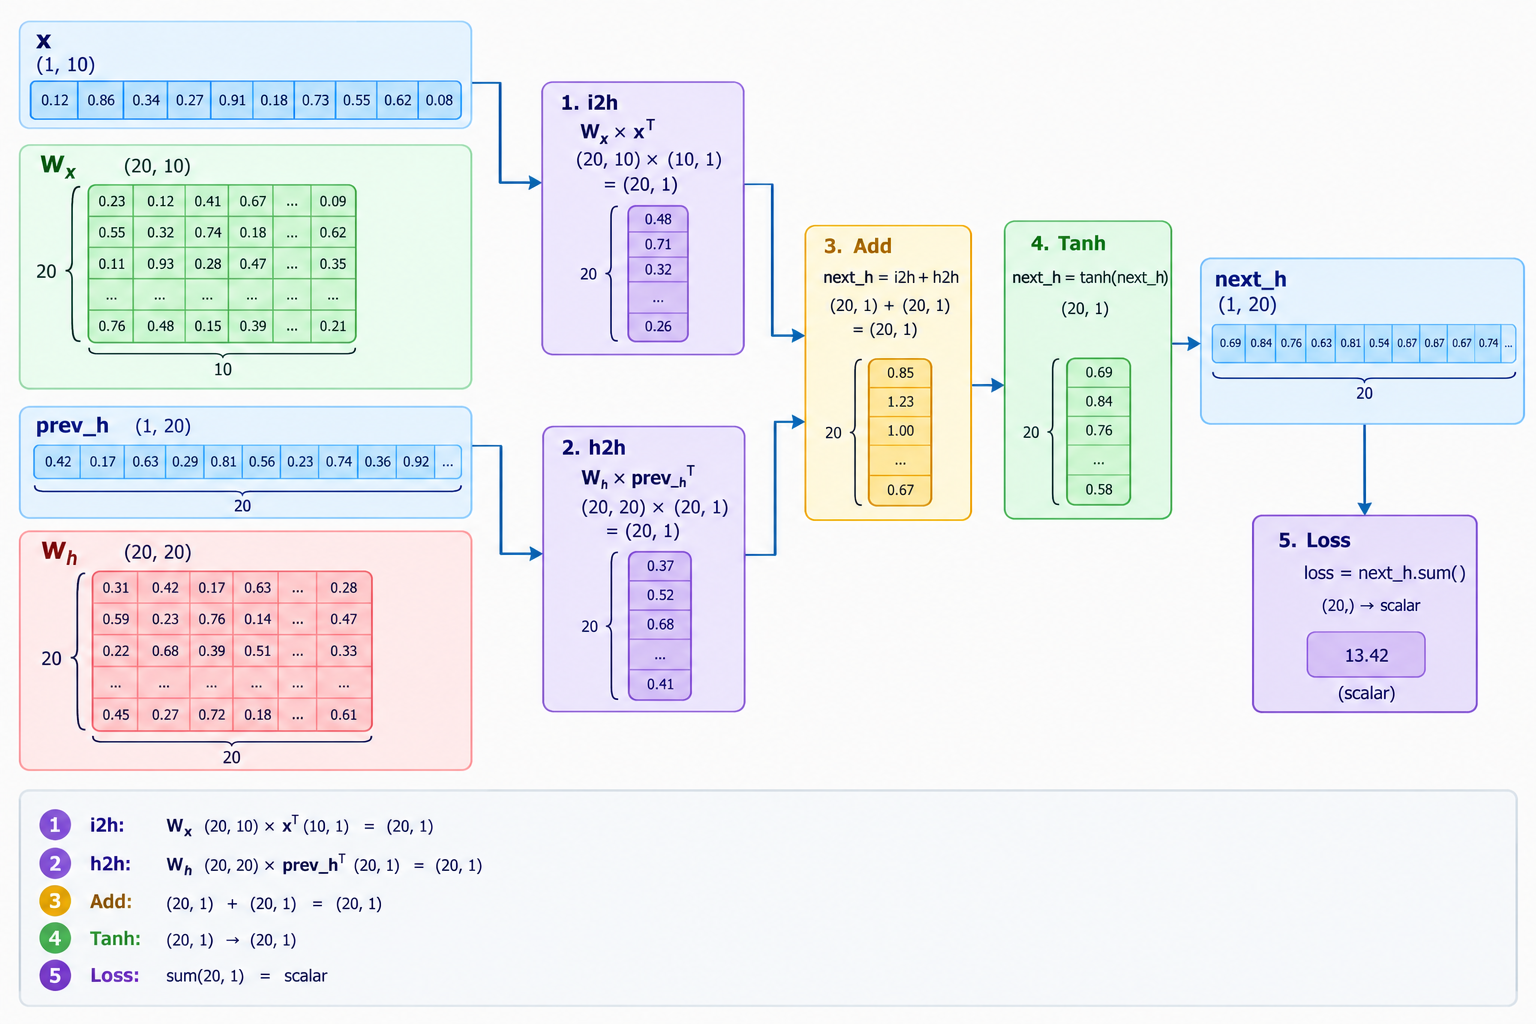

# Building Model

In [27]:
import torch
import torch.nn as nn
import torch.nn.functional as F

In [37]:
class Lenet(nn.Module):
    def __init__(self ):
        super(Lenet, self).__init__()

        # Input Channel, Output_channel, kernel size
        self.conv1= nn.Conv2d(1,6,3)
        self.conv2= nn.Conv2d(6,16,3)


        self.fc1= nn.Linear(16*6*6, 120)
        self.fc2= nn.Linear(120,84)
        self.fc3= nn.Linear(84,10)

    def num_flat_features(self, x):
        size= x.size()[1:]
        num_features=1
        for s in size:
            num_features*=s
        return num_features

    def forward(self, x):
        # Max pooling over 2x2 window
        x= F.max_pool2d(F.relu(self.conv1(x)), (2,2))

        x= F.max_pool2d(F.relu(self.conv2(x)), 2)

        x= x.view(-1, self.num_flat_features(x))
        x=F.relu(self.fc1(x))
        x= F.relu(self.fc2(x))


        x= self.fc3(x)
        return x

In [39]:
net= Lenet()
print(net)

input = torch.rand(1,1,32,32)
print(f"\n Shape of input : {input.shape}")

output= net(input)
print(f"Raw Output Shape: {output.shape}")
print(f"\nOutput: {output}")

Lenet(
  (conv1): Conv2d(1, 6, kernel_size=(3, 3), stride=(1, 1))
  (conv2): Conv2d(6, 16, kernel_size=(3, 3), stride=(1, 1))
  (fc1): Linear(in_features=576, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)

 Shape of input : torch.Size([1, 1, 32, 32])
Raw Output Shape: torch.Size([1, 10])

Output: tensor([[ 0.1064, -0.0141, -0.1382, -0.0796,  0.0064,  0.0492,  0.0519, -0.0351,
          0.0616,  0.0439]], grad_fn=<AddmmBackward0>)


# Dataset & DataLoader

In [46]:

import torch
import torchvision
import torchvision.transforms as transforms

In [ ]:
transform= transforms.Compose([
    transforms.ToTensor(),
    # Normalize: mean & std to 0.5
    transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5))
])

In [52]:
trainset= torchvision.datasets.CIFAR10(root="./", train= True, download=True, transform=transform)

In [ ]:
trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=4,
    shuffle=True,
    num_workers=2
)

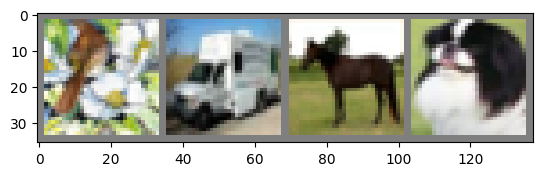

bird truck horse dog


In [57]:
import matplotlib.pyplot as plt
import numpy as np



classes = (
    "plane", "car", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
)

def imshow(img):
    img = img / 2 + 0.5  # Unnormalize the image
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()

dataiter = iter(trainloader)
images, labels = next(dataiter)

imshow(torchvision.utils.make_grid(images))

print(" ".join(f"{classes[labels[j]]}" for j in range(4)))

# Trainig Model

In [58]:
import torch 
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

import torchvision
import torchvision.transforms as transforms

import matplotlib
import matplotlib.pyplot as plt 
import numpy as np

In [59]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5))
])

trainset= torchvision.datasets.CIFAR10(root="./", train= True, download=True, transform=transform)

trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=4,
    shuffle=True,
    num_workers=2
)

testset= torchvision.datasets.CIFAR10(root="./", train=False, download=True, transform=transform)

testloader= torch.utils.data.DataLoader(
    testset, 
    batch_size=4,
    shuffle=False, 
    num_workers=2
)

classes = (
    "plane", "car", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
)

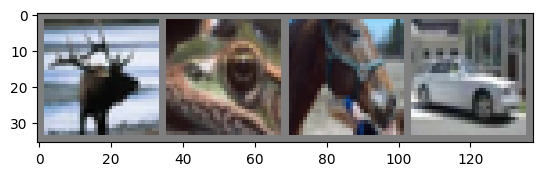

deer frog horse car


In [60]:
def imshow(img):
    img = img / 2 + 0.5  # Unnormalize the image
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()

dataiter = iter(trainloader)
images, labels = next(dataiter)

imshow(torchvision.utils.make_grid(images))

print(" ".join(f"{classes[labels[j]]}" for j in range(4)))

In [61]:
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()

        self.conv1= nn.Conv2d(3, 6, 5)
        self.pool= nn.MaxPool2d(2,2)
        self.conv2= nn.Conv2d(6, 16, 5)
        self.fc1= nn.Linear(16*5*5, 120)
        self.fc2= nn.Linear(120, 84)
        self.fc3= nn.Linear(84, 10)

    def forward(self, x):
        x= self.pool(F.relu(self.conv1(x)))
        x= self.pool(F.relu(self.conv2(x)))
        x= x.view(-1,16*5*5)
        x= F.relu(self.fc1(x))
        x= F.relu(self.fc2(x))
        x= self.fc3(x)
        return x

net=Net()

In [63]:
criterion= nn.CrossEntropyLoss()
# Stocastic Gradient Descent
optimizer= optim.SGD(net.parameters(), lr=0.001, momentum=0.9)

In [65]:
for epoch in range(2):
    running_loss=0.0
    for i, data in enumerate(trainloader,0):
        inputs, labels= data
        optimizer.zero_grad()

        outputs= net(inputs)
        loss= criterion(outputs, labels)
        loss.backward()
        optimizer.step()


        running_loss+=loss.item()

        if i % 2000==1999:
            print('[%d, %5d] loss: %.3f' % (epoch+1, i+1, running_loss/2000))
            running_loss=0
print("Finished Traning")


[1,  2000] loss: 1.814
[1,  4000] loss: 1.665
[1,  6000] loss: 1.549
[1,  8000] loss: 1.492
[1, 10000] loss: 1.450
[1, 12000] loss: 1.406
[2,  2000] loss: 1.343
[2,  4000] loss: 1.337
[2,  6000] loss: 1.302
[2,  8000] loss: 1.281
[2, 10000] loss: 1.259
[2, 12000] loss: 1.252
Finished Traning


In [68]:
correct=0
total=0

with torch.no_grad():
    for data in testloader:
        images, labels= data
        outputs= net(images)
        _, predicted= torch.max(outputs.data, 1)
        total+= labels.size(0)
        correct+= (predicted==labels).sum().item()

print("Accuracy of the network of 10000 test images %d %%", (100*correct/total))

Accuracy of the network of 10000 test images %d %% 56.79


# Deployment with torchscript

In [69]:
my_script_module= torch.jit.script(net)
my_script_module.save("net_module.pt")